# ПР3. Згортка. Розробка згорткової нейронної мережі
**Датасет:** CIFAR-10 (варіант 2) · **Бібліотеки:** TensorFlow / Keras

In [1]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import regularizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv2D, MaxPooling2D, AveragePooling2D, Flatten, Dense,
                                     Dropout, BatchNormalization, Activation, Lambda)
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import cifar10
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
EPOCHS = 15
BATCH_SIZE = 256
N_RUNS = 3          # кількість запусків на конфігурацію (різні seed)

keras.utils.set_random_seed(SEED)
tf.get_logger().setLevel('ERROR')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
os.makedirs('outputs', exist_ok=True)

print('TensorFlow', tf.__version__, '| Keras', keras.__version__)
print('Параметри: EPOCHS =', EPOCHS, '| BATCH_SIZE =', BATCH_SIZE, '| N_RUNS =', N_RUNS)

TensorFlow 2.21.0 | Keras 3.14.1
Параметри: EPOCHS = 15 | BATCH_SIZE = 256 | N_RUNS = 3


## Завдання 1. Розробка згорткової нейронної мережі для датасету за варіантом
> Розробити згорткову нейронну мережу для датасету зображень відповідно до варіанту завдань.

### 1.1 Датасет CIFAR-10

In [2]:
CLASS_NAMES = ['літак', 'автомобіль', 'птах', 'кіт', 'олень',
               'собака', 'жаба', 'кінь', 'корабель', 'вантажівка']

(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = cifar10.load_data()
y_train_raw, y_test_raw = y_train_raw.flatten(), y_test_raw.flatten()

print('train:', x_train_raw.shape, x_train_raw.dtype, '| test:', x_test_raw.shape)
print('діапазон пікселів:', x_train_raw.min(), '…', x_train_raw.max())
print('зображень на клас (train):', np.bincount(y_train_raw))
print('зображень на клас (test): ', np.bincount(y_test_raw))

train: (50000, 32, 32, 3) uint8 | test: (10000, 32, 32, 3)
діапазон пікселів: 0 … 255
зображень на клас (train): [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
зображень на клас (test):  [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


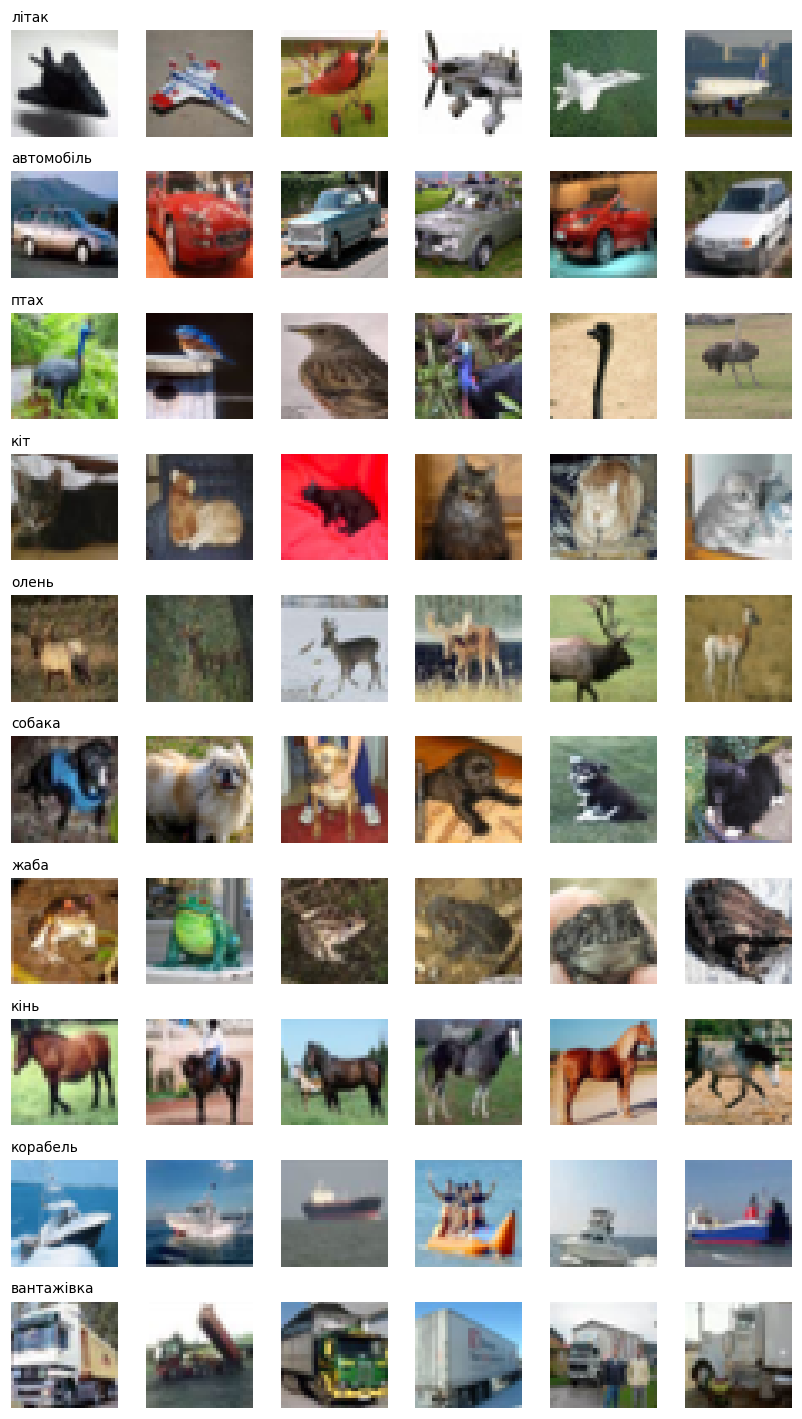

In [3]:
fig, axes = plt.subplots(10, 6, figsize=(7.5, 13))
for c in range(10):
    for j, i in enumerate(np.where(y_train_raw == c)[0][:6]):
        ax = axes[c, j]
        ax.imshow(x_train_raw[i])
        ax.axis('off')
        if j == 0:
            ax.set_title(CLASS_NAMES[c], fontsize=9, loc='left')
plt.tight_layout()
plt.show()

### 1.2 Попередня обробка даних

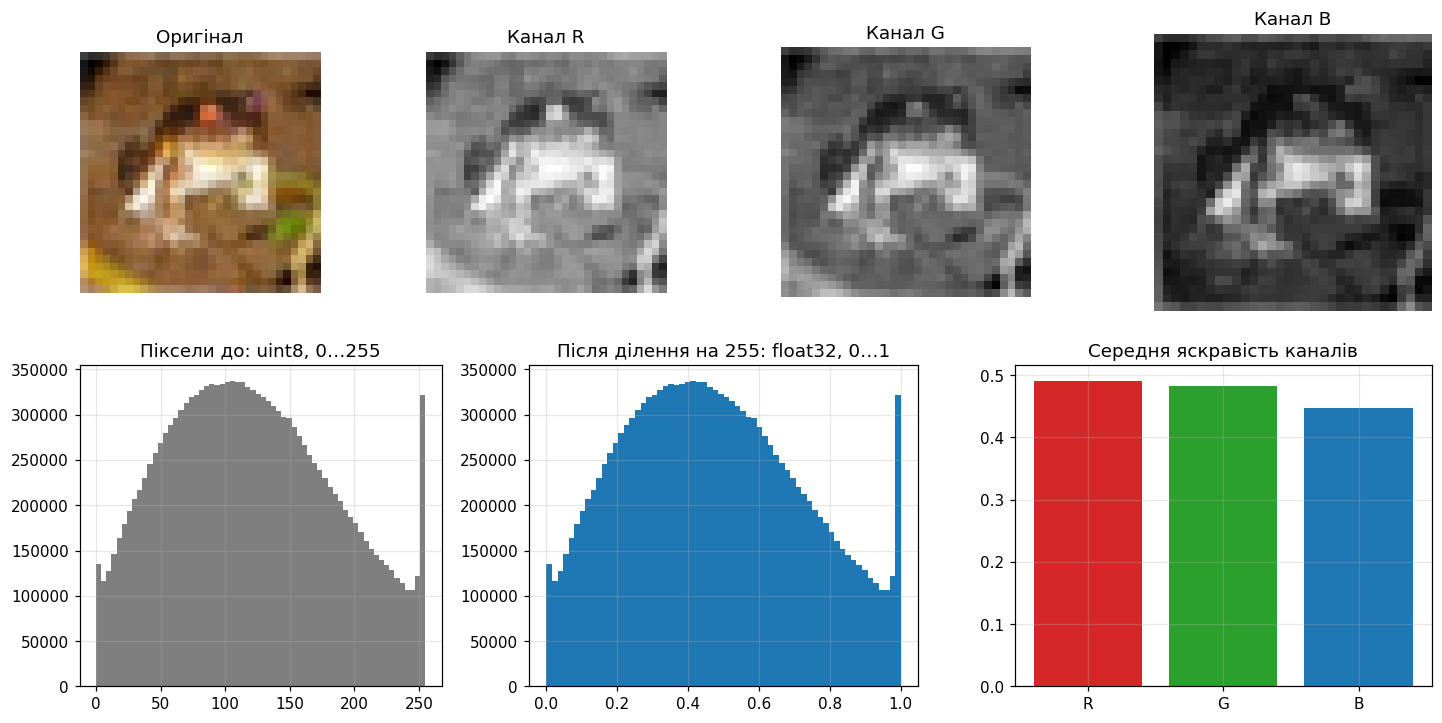

Піксель [0, 0] (R, G, B) до : [59 62 63] | після: [0.2314 0.2431 0.2471]


In [4]:
img = x_train_raw[0]
x_scaled = x_train_raw.astype('float32') / 255.

fig = plt.figure(figsize=(13, 6.5), constrained_layout=True)
gs = fig.add_gridspec(2, 12)
titles = ['Оригінал', 'Канал R', 'Канал G', 'Канал B']
for k in range(4):
    ax = fig.add_subplot(gs[0, 3 * k:3 * k + 3])
    ax.imshow(img if k == 0 else img[..., k - 1], cmap=None if k == 0 else 'gray', vmin=0, vmax=255)
    ax.set_title(titles[k]); ax.axis('off')

ax = fig.add_subplot(gs[1, 0:4])
ax.hist(x_train_raw[:5000].ravel(), bins=64, color='tab:gray')
ax.set_title('Піксели до: uint8, 0…255')

ax = fig.add_subplot(gs[1, 4:8])
ax.hist(x_scaled[:5000].ravel(), bins=64, color='tab:blue')
ax.set_title('Після ділення на 255: float32, 0…1')

ax = fig.add_subplot(gs[1, 8:12])
ax.bar(['R', 'G', 'B'], x_scaled.mean(axis=(0, 1, 2)), color=['tab:red', 'tab:green', 'tab:blue'])
ax.set_title('Середня яскравість каналів')
plt.show()

print('Піксель [0, 0] (R, G, B) до :', img[0, 0], '| після:', x_scaled[0, 0, 0].round(4))

In [5]:
x_test = x_test_raw.astype('float32') / 255.

# валідаційна вибірка виділяється з навчальної; тестова лишається недоторканою
x_train, x_val, y_train_lbl, y_val_lbl = train_test_split(
    x_scaled, y_train_raw, test_size=0.1, stratify=y_train_raw, random_state=SEED)

y_train = to_categorical(y_train_lbl, 10)
y_val = to_categorical(y_val_lbl, 10)
y_test = to_categorical(y_test_raw, 10)

print('train:', x_train.shape, y_train.shape)
print('val:  ', x_val.shape, y_val.shape)
print('test: ', x_test.shape, y_test.shape)
print('мітка кота до one-hot:', y_train_lbl[y_train_lbl == 3][0], '→', y_train[y_train_lbl == 3][0])

train: (45000, 32, 32, 3) (45000, 10)
val:   (5000, 32, 32, 3) (5000, 10)
test:  (10000, 32, 32, 3) (10000, 10)
мітка кота до one-hot: 3 → [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]


### 1.3 Структура базової моделі

In [6]:
def build_base():
    model = Sequential([
        keras.Input(shape=(32, 32, 3)),
        Conv2D(32, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Conv2D(64, kernel_size=(3, 3), activation='relu'),
        MaxPooling2D(pool_size=(2, 2)),
        Flatten(),
        Dense(128, activation='relu'),
        Dense(10, activation='softmax'),
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model


model = build_base()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
def conv_out(w, f, p=0, s=1):
    return (w - f + 2 * p) // s + 1       # floor((W - F + 2P) / S) + 1


h, c, n = 32, 3, None
rows = []
for layer in model.layers:
    if isinstance(layer, Conv2D):
        f, k = layer.kernel_size[0], layer.filters
        h, params, c = conv_out(h, f), (f * f * c + 1) * k, k
        shape = (h, h, c)
    elif isinstance(layer, MaxPooling2D):
        h, params = conv_out(h, layer.pool_size[0], s=layer.strides[0]), 0
        shape = (h, h, c)
    elif isinstance(layer, Flatten):
        n, params = h * h * c, 0
        shape = (n,)
    else:
        params, n = (n + 1) * layer.units, layer.units
        shape = (n,)
    rows.append([layer.name, shape, tuple(layer.output.shape[1:]), params, layer.count_params()])

check = pd.DataFrame(rows, columns=['шар', 'розмір (розрахунок)', 'розмір (Keras)',
                                    'параметри (розрахунок)', 'параметри (Keras)'])
check['збіг'] = [r[1] == r[2] and r[3] == r[4] for r in rows]
print(check.to_string(index=False))
print('Всього параметрів:', check['параметри (Keras)'].sum())

            шар розмір (розрахунок) розмір (Keras)  параметри (розрахунок)  параметри (Keras)  збіг
         conv2d        (30, 30, 32)   (30, 30, 32)                     896                896  True
  max_pooling2d        (15, 15, 32)   (15, 15, 32)                       0                  0  True
       conv2d_1        (13, 13, 64)   (13, 13, 64)                   18496              18496  True
max_pooling2d_1          (6, 6, 64)     (6, 6, 64)                       0                  0  True
        flatten             (2304,)        (2304,)                       0                  0  True
          dense              (128,)         (128,)                  295040             295040  True
        dense_1               (10,)          (10,)                    1290               1290  True
Всього параметрів: 315722


### 1.4 Навчання базової моделі

In [8]:
keras.utils.set_random_seed(SEED)
model = build_base()
t0 = time.time()
history = model.fit(x_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                    validation_data=(x_val, y_val), verbose=2)
print(f'Час навчання: {time.time() - t0:.0f} с')

loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f'Точність моделі на тесті: {accuracy * 100:.2f}%  (loss = {loss:.4f})')

Epoch 1/15


176/176 - 3s - 19ms/step - accuracy: 0.4168 - loss: 1.6203 - val_accuracy: 0.5188 - val_loss: 1.3775


Epoch 2/15


176/176 - 3s - 14ms/step - accuracy: 0.5538 - loss: 1.2730 - val_accuracy: 0.5904 - val_loss: 1.1871


Epoch 3/15


...

176/176 - 2s - 14ms/step - accuracy: 0.7742 - loss: 0.6617 - val_accuracy: 0.6882 - val_loss: 0.9247


Epoch 15/15


176/176 - 2s - 14ms/step - accuracy: 0.7817 - loss: 0.6374 - val_accuracy: 0.6906 - val_loss: 0.9211


Час навчання: 39 с


Точність моделі на тесті: 69.00%  (loss = 0.9396)


### 1.5 Криві навчання, матриця помилок, метрики (базова модель)

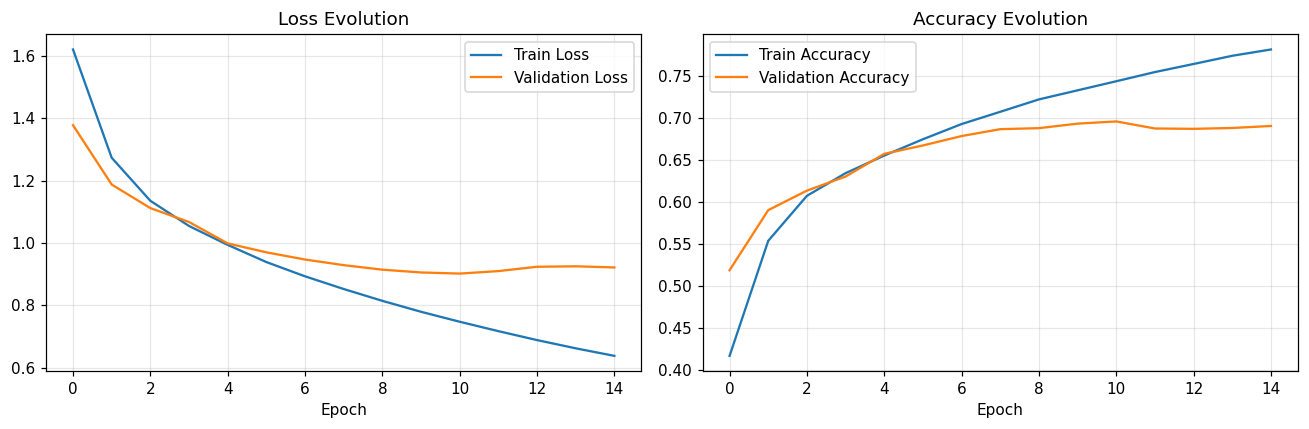

Мінімум val_loss: епоха 11 (0.9014); останній val_loss: 0.9211


In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend(); plt.title('Loss Evolution'); plt.xlabel('Epoch')

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend(); plt.title('Accuracy Evolution'); plt.xlabel('Epoch')

plt.tight_layout()
plt.show()

best_ep = int(np.argmin(history.history['val_loss'])) + 1
print(f'Мінімум val_loss: епоха {best_ep} ({min(history.history["val_loss"]):.4f}); '
      f'останній val_loss: {history.history["val_loss"][-1]:.4f}')

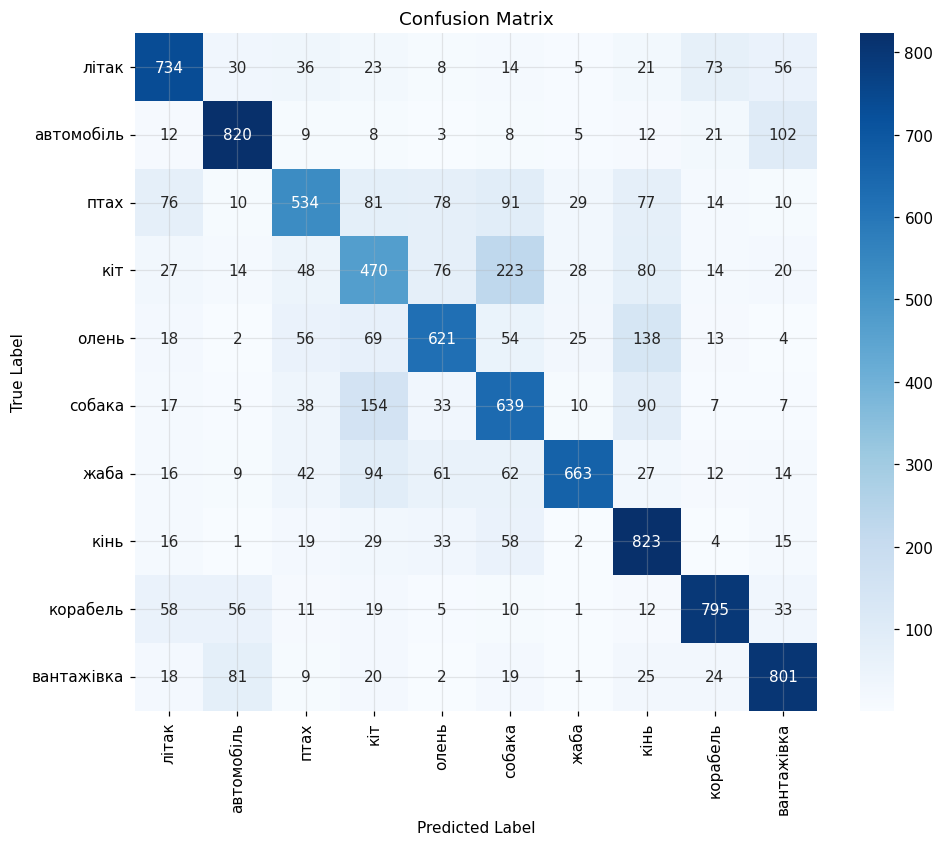

In [10]:
y_pred = model.predict(x_test, verbose=0)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

conf_mtx = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_mtx, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted Label'); plt.ylabel('True Label'); plt.title('Confusion Matrix')
plt.show()

In [11]:
print('Classification Report:\n')
print(classification_report(y_true, y_pred_classes, target_names=CLASS_NAMES, digits=4, zero_division=0))
f1_base = classification_report(y_true, y_pred_classes, target_names=CLASS_NAMES, output_dict=True, zero_division=0)

Classification Report:

              precision    recall  f1-score   support

       літак     0.7399    0.7340    0.7369      1000
  автомобіль     0.7977    0.8200    0.8087      1000
        птах     0.6658    0.5340    0.5927      1000
         кіт     0.4860    0.4700    0.4779      1000
       олень     0.6750    0.6210    0.6469      1000
      собака     0.5424    0.6390    0.5868      1000
        жаба     0.8622    0.6630    0.7496      1000
        кінь     0.6307    0.8230    0.7141      1000
    корабель     0.8137    0.7950    0.8042      1000
  вантажівка     0.7542    0.8010    0.7769      1000

    accuracy                         0.6900     10000
   macro avg     0.6968    0.6900    0.6895     10000
weighted avg     0.6968    0.6900    0.6895     10000



Найчастіші помилки (факт → прогноз):
         кіт → собака     223 випадків
      собака → кіт        154 випадків
       олень → кінь       138 випадків
  автомобіль → вантажівка 102 випадків
        жаба → кіт        94 випадків
        птах → собака     91 випадків


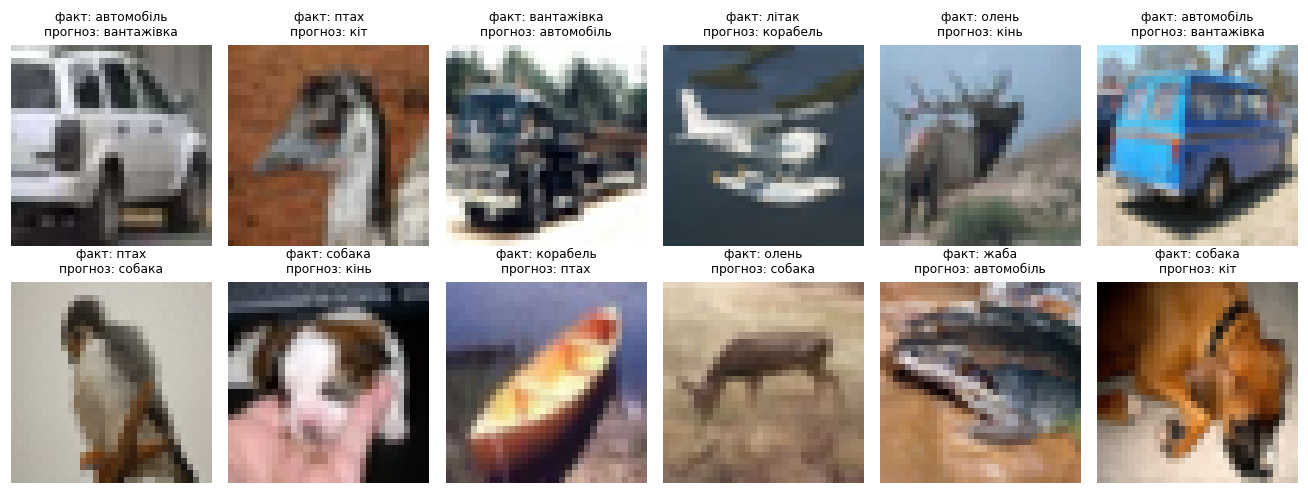

Помилок на тесті: 3100 із 10000


In [12]:
off = conf_mtx.copy()
np.fill_diagonal(off, 0)
print('Найчастіші помилки (факт → прогноз):')
for flat in np.argsort(off.ravel())[::-1][:6]:
    t, p = np.unravel_index(flat, off.shape)
    print(f'  {CLASS_NAMES[t]:>10} → {CLASS_NAMES[p]:<10} {off[t, p]} випадків')

wrong = np.where(y_pred_classes != y_true)[0]
pick = np.random.default_rng(SEED).choice(wrong, 12, replace=False)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
for ax, i in zip(axes.ravel(), pick):
    ax.imshow(x_test[i]); ax.axis('off')
    ax.set_title(f'факт: {CLASS_NAMES[y_true[i]]}\nпрогноз: {CLASS_NAMES[y_pred_classes[i]]}', fontsize=8)
plt.tight_layout()
plt.show()
print(f'Помилок на тесті: {len(wrong)} із {len(y_true)}')

## Завдання 2. Вплив оптимізаторів, функцій активації та регуляризацій
> Дослідити вплив та порівняти результати роботи різних оптимізаторів (Adam, SGD, RMSprop, функцій активації (relu, elu, sigmoid, tanh, і т.д.) та регуляризацій (L1, L2, Dropout, Batch Normalization).

### 2.0 Допоміжні функції експерименту

In [13]:
def build_cnn(filters=(32, 64), kernel=3, padding='valid', activation='relu', dense=128,
              reg=None, dropout=False, batchnorm=False, double=False,
              pool='max', pool_size=2, conv_stride=1):
    model = Sequential([keras.Input(shape=(32, 32, 3))])
    for f in filters:
        for _ in range(2 if double else 1):
            model.add(Conv2D(f, (kernel, kernel), strides=conv_stride, padding=padding,
                             kernel_regularizer=reg,
                             activation=None if batchnorm else activation))
            if batchnorm:
                model.add(BatchNormalization())
                model.add(Activation(activation))
        if pool == 'max':
            model.add(MaxPooling2D((pool_size, pool_size)))
        elif pool == 'avg':
            model.add(AveragePooling2D((pool_size, pool_size)))
        elif pool == 'min':                      # min(x) = -max(-x)
            model.add(Lambda(lambda x: -x))
            model.add(MaxPooling2D((pool_size, pool_size)))
            model.add(Lambda(lambda x: -x))
        if dropout:
            model.add(Dropout(0.25))
    model.add(Flatten())
    model.add(Dense(dense, activation=activation, kernel_regularizer=reg))
    if dropout:
        model.add(Dropout(0.5))
    model.add(Dense(10, activation='softmax'))
    return model


def make_optimizer(name):
    if name == 'sgd_momentum':
        return keras.optimizers.SGD(learning_rate=0.01, momentum=0.9)
    return keras.optimizers.get(name)


assert build_cnn().count_params() == build_base().count_params()

results, histories, preds = [], {}, {}


def run_experiment(name, group, optimizer='adam', base=False, keep_pred=False, **arch):
    runs = []
    for r in range(N_RUNS):
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED + r)
        m = build_cnn(**arch)
        m.compile(optimizer=make_optimizer(optimizer), loss='categorical_crossentropy',
                  metrics=['accuracy'])
        t0 = time.time()
        h = m.fit(x_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE,
                  validation_data=(x_val, y_val), verbose=0)
        _, test_acc = m.evaluate(x_test, y_test, verbose=0)
        runs.append(dict(train=h.history['accuracy'][-1], val=h.history['val_accuracy'][-1],
                         best_val=max(h.history['val_accuracy']), test=test_acc,
                         time=time.time() - t0, params=m.count_params()))
        if r == 0:
            histories[name] = {k: [float(v) for v in vals] for k, vals in h.history.items()}
            if keep_pred:
                preds[name] = m.predict(x_test, verbose=0)
    mean = lambda k: float(np.mean([x[k] for x in runs]))
    row = {'група': group, 'назва': name, 'база': base,
           'train_acc': mean('train'), 'val_acc': mean('val'),
           'test_acc': mean('test'), 'test_std': float(np.std([x['test'] for x in runs])),
           'розрив': mean('train') - mean('val'), 'параметри': runs[0]['params'],
           'час_с': mean('time')}
    results.append(row)
    print(f"{group:<15}{name:<38} train={row['train_acc']:.4f}  val={row['val_acc']:.4f}  "
          f"test={row['test_acc']:.4f}±{row['test_std']:.4f}  параметри={row['параметри']:>7,}  "
          f"{row['час_с']:.0f} с/запуск")


def show_group(group, title):
    df = pd.DataFrame(results)
    d = df[(df['група'] == group) | df['база']].reset_index(drop=True)
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
    for nm in d['назва']:
        ax[0].plot(histories[nm]['val_accuracy'], label=nm)
        ax[1].plot(histories[nm]['val_loss'], label=nm)
    ax[0].set_title('Validation Accuracy'); ax[1].set_title('Validation Loss')
    for a in ax[:2]:
        a.set_xlabel('Epoch'); a.legend(fontsize=7)
    ax[2].barh(d['назва'], d['test_acc'], xerr=d['test_std'], color='tab:blue')
    ax[2].set_xlim(max(0, d['test_acc'].min() - 0.08), min(1, d['test_acc'].max() + 0.04))
    ax[2].set_title('Test Accuracy (середнє ± std)'); ax[2].invert_yaxis()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
    cols = ['назва', 'train_acc', 'val_acc', 'test_acc', 'test_std', 'розрив', 'параметри', 'час_с']
    print(d[cols].round(4).to_string(index=False))

### 2.0.1 Базова конфігурація (Adam, ReLU, без регуляризації)

In [14]:
run_experiment('Базова (Adam, ReLU)', 'база', base=True)

база           Базова (Adam, ReLU)                    train=0.7717  val=0.6925  test=0.6904±0.0019  параметри=315,722  39 с/запуск


### 2.1 Оптимізатори: Adam, SGD, RMSprop

оптимізатор    SGD                                    train=0.4704  val=0.4686  test=0.4727±0.0019  параметри=315,722  37 с/запуск


оптимізатор    RMSprop                                train=0.8083  val=0.6965  test=0.6905±0.0074  параметри=315,722  38 с/запуск


оптимізатор    SGD + momentum 0.9                     train=0.7472  val=0.6630  test=0.6572±0.0110  параметри=315,722  38 с/запуск


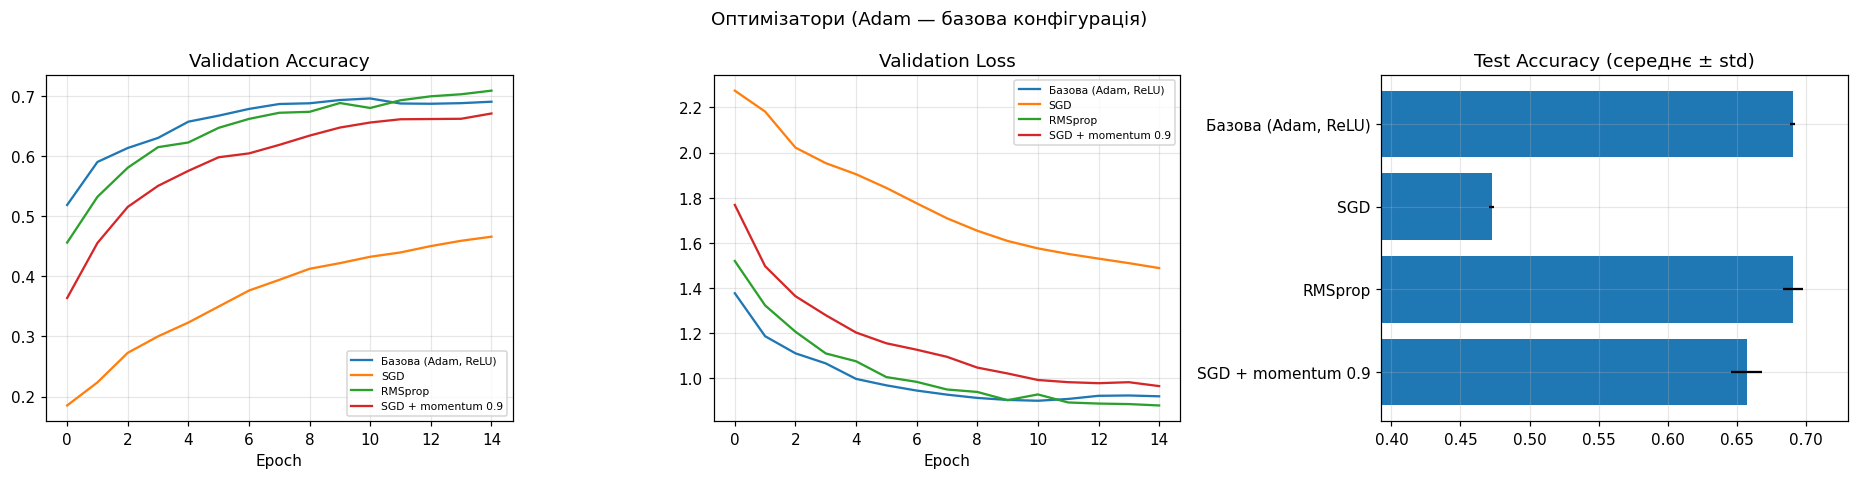

              назва  train_acc  val_acc  test_acc  test_std  розрив  параметри   час_с
Базова (Adam, ReLU)     0.7717   0.6925    0.6904    0.0019  0.0793     315722 39.0183
                SGD     0.4704   0.4686    0.4727    0.0019  0.0018     315722 37.4578
            RMSprop     0.8083   0.6965    0.6905    0.0074  0.1118     315722 38.3028
 SGD + momentum 0.9     0.7472   0.6630    0.6572    0.0110  0.0842     315722 38.3358


In [15]:
for name, opt in [('SGD', 'sgd'), ('RMSprop', 'rmsprop'), ('SGD + momentum 0.9', 'sgd_momentum')]:
    run_experiment(name, 'оптимізатор', optimizer=opt)
show_group('оптимізатор', 'Оптимізатори (Adam — базова конфігурація)')

### 2.2 Функції активації: relu, elu, sigmoid, tanh, leaky_relu

активація      elu                                    train=0.8565  val=0.6809  test=0.6822±0.0045  параметри=315,722  40 с/запуск


активація      sigmoid                                train=0.5006  val=0.4875  test=0.4888±0.0083  параметри=315,722  43 с/запуск


активація      tanh                                   train=0.8497  val=0.6550  test=0.6553±0.0048  параметри=315,722  40 с/запуск


активація      leaky_relu                             train=0.8148  val=0.6867  test=0.6902±0.0080  параметри=315,722  46 с/запуск


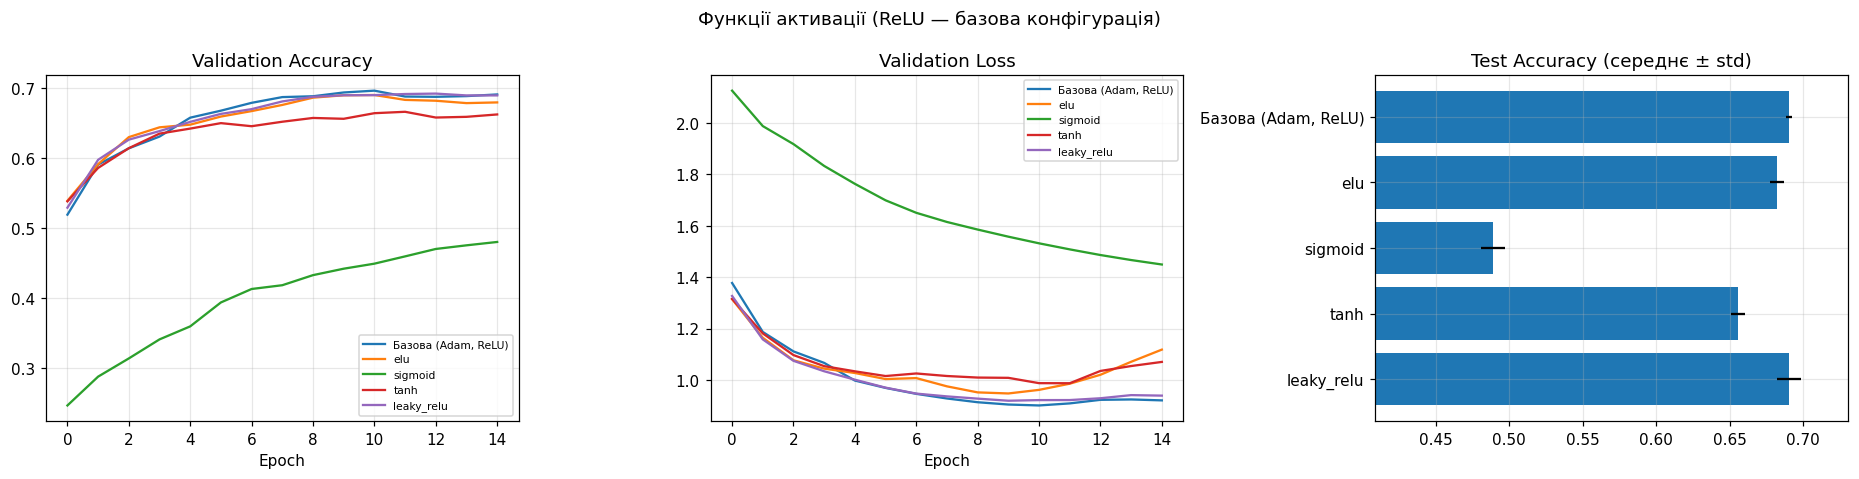

              назва  train_acc  val_acc  test_acc  test_std  розрив  параметри   час_с
Базова (Adam, ReLU)     0.7717   0.6925    0.6904    0.0019  0.0793     315722 39.0183
                elu     0.8565   0.6809    0.6822    0.0045  0.1755     315722 39.6100
            sigmoid     0.5006   0.4875    0.4888    0.0083  0.0132     315722 42.8937
               tanh     0.8497   0.6550    0.6553    0.0048  0.1947     315722 40.1817
         leaky_relu     0.8148   0.6867    0.6902    0.0080  0.1282     315722 45.5094


In [16]:
for act in ['elu', 'sigmoid', 'tanh', 'leaky_relu']:
    run_experiment(act, 'активація', activation=act)
show_group('активація', 'Функції активації (ReLU — базова конфігурація)')

### 2.3 Регуляризації: L1, L2, Dropout, Batch Normalization

регуляризація  L1 (1e-05)                             train=0.7625  val=0.6884  test=0.6853±0.0110  параметри=315,722  40 с/запуск


регуляризація  L2 (0.0001)                            train=0.7648  val=0.6887  test=0.6859±0.0053  параметри=315,722  39 с/запуск


регуляризація  Dropout (0.25 / 0.5)                   train=0.6375  val=0.6847  test=0.6811±0.0131  параметри=315,722  45 с/запуск


регуляризація  BatchNorm                              train=0.8336  val=0.6579  test=0.6543±0.0081  параметри=316,106  96 с/запуск


регуляризація  BatchNorm + Dropout                    train=0.5197  val=0.6303  test=0.6271±0.0097  параметри=316,106  102 с/запуск


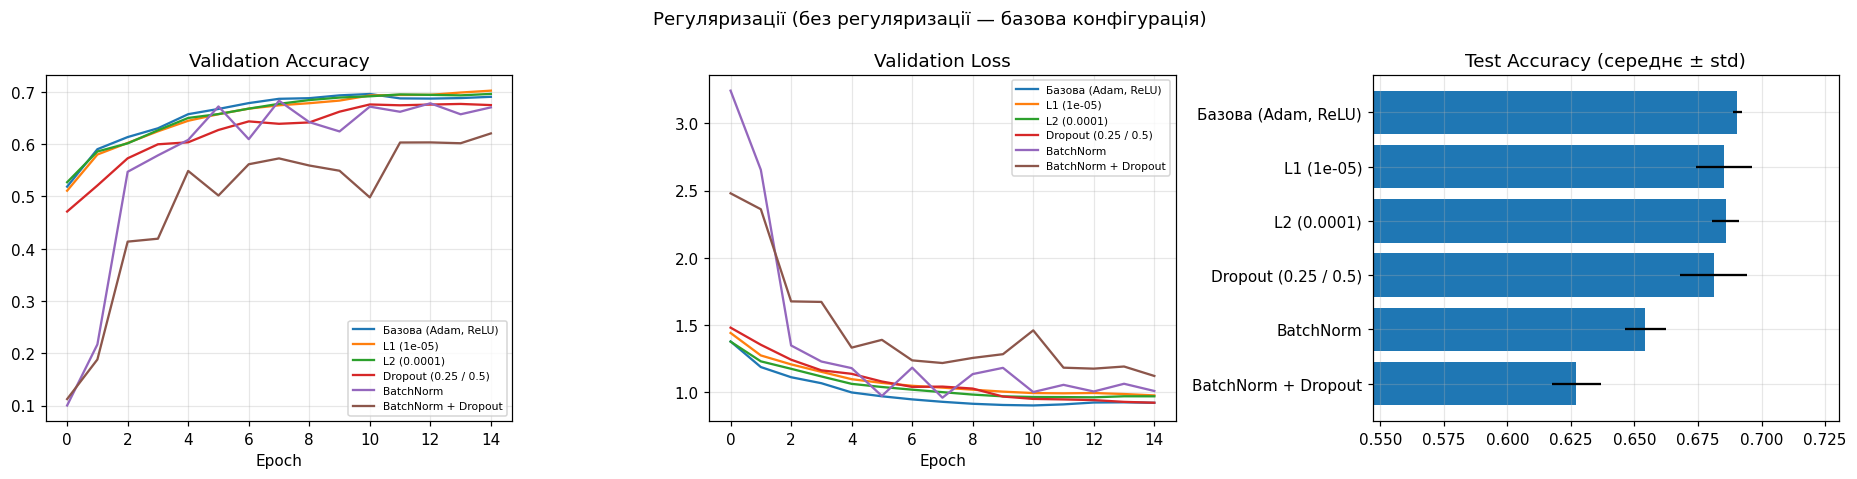

               назва  train_acc  val_acc  test_acc  test_std  розрив  параметри    час_с
 Базова (Adam, ReLU)     0.7717   0.6925    0.6904    0.0019  0.0793     315722  39.0183
          L1 (1e-05)     0.7625   0.6884    0.6853    0.0110  0.0741     315722  40.0709
         L2 (0.0001)     0.7648   0.6887    0.6859    0.0053  0.0760     315722  38.8888
Dropout (0.25 / 0.5)     0.6375   0.6847    0.6811    0.0131 -0.0472     315722  44.6433
           BatchNorm     0.8336   0.6579    0.6543    0.0081  0.1757     316106  96.0292
 BatchNorm + Dropout     0.5197   0.6303    0.6271    0.0097 -0.1106     316106 102.0895


In [17]:
L1, L2 = 1e-5, 1e-4
for name, arch in [(f'L1 ({L1})', dict(reg=regularizers.l1(L1))),
                   (f'L2 ({L2})', dict(reg=regularizers.l2(L2))),
                   ('Dropout (0.25 / 0.5)', dict(dropout=True)),
                   ('BatchNorm', dict(batchnorm=True)),
                   ('BatchNorm + Dropout', dict(batchnorm=True, dropout=True))]:
    run_experiment(name, 'регуляризація', **arch)
show_group('регуляризація', 'Регуляризації (без регуляризації — базова конфігурація)')

## Завдання 3. Інша архітектура базової мережі
> Спробувати іншу архітектуру базової мережі, збільшити або зменшити кількість шарів, розміри, тощо (згорткових та пулінгових, і т.д.).

### 3.1 Згорткові шари: кількість, фільтри, ядро, паддінг

архітектура    1 згорткова (32)                       train=0.7452  val=0.6477  test=0.6380±0.0085  параметри=923,914  28 с/запуск


архітектура    Вузька (16-32)                         train=0.7137  val=0.6586  test=0.6541±0.0071  параметри=153,962  18 с/запуск


архітектура    Широка (64-128)                        train=0.8151  val=0.6979  test=0.6985±0.0034  параметри=666,890  102 с/запуск


архітектура    Ядро 5×5 (32-64)                       train=0.7699  val=0.6707  test=0.6644±0.0046  параметри=259,914  45 с/запуск


архітектура    Базова + padding same                  train=0.7992  val=0.6962  test=0.6922±0.0027  параметри=545,098  50 с/запуск


архітектура    3 згорткові (32-64-128), same          train=0.8337  val=0.7137  test=0.7131±0.0055  параметри=356,810  66 с/запуск


архітектура    Блоки 2×Conv (32-64-128), same         train=0.9049  val=0.7451  test=0.7384±0.0104  параметри=550,570  183 с/запуск


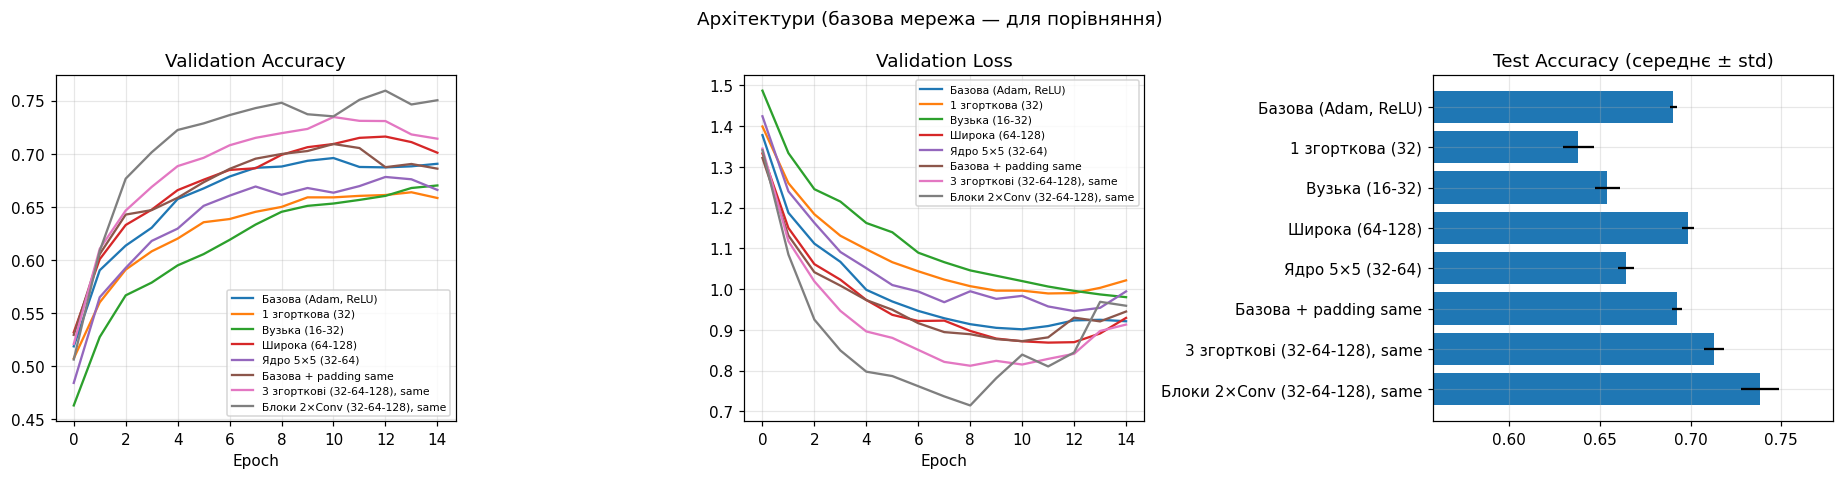

                         назва  train_acc  val_acc  test_acc  test_std  розрив  параметри    час_с
           Базова (Adam, ReLU)     0.7717   0.6925    0.6904    0.0019  0.0793     315722  39.0183
              1 згорткова (32)     0.7452   0.6477    0.6380    0.0085  0.0975     923914  28.4538
                Вузька (16-32)     0.7137   0.6586    0.6541    0.0071  0.0551     153962  17.9662
               Широка (64-128)     0.8151   0.6979    0.6985    0.0034  0.1172     666890 101.7419
              Ядро 5×5 (32-64)     0.7699   0.6707    0.6644    0.0046  0.0992     259914  45.1553
         Базова + padding same     0.7992   0.6962    0.6922    0.0027  0.1030     545098  49.7596
 3 згорткові (32-64-128), same     0.8337   0.7137    0.7131    0.0055  0.1199     356810  66.3340
Блоки 2×Conv (32-64-128), same     0.9049   0.7451    0.7384    0.0104  0.1598     550570 183.1445


In [18]:
ARCHS = [
    ('1 згорткова (32)',                 dict(filters=(32,))),
    ('Вузька (16-32)',                   dict(filters=(16, 32))),
    ('Широка (64-128)',                  dict(filters=(64, 128))),
    ('Ядро 5×5 (32-64)',                 dict(filters=(32, 64), kernel=5)),
    ('Базова + padding same',            dict(padding='same')),
    ('3 згорткові (32-64-128), same',    dict(filters=(32, 64, 128), padding='same')),
    ('Блоки 2×Conv (32-64-128), same',   dict(filters=(32, 64, 128), padding='same', double=True)),
]
for name, arch in ARCHS:
    run_experiment(name, 'архітектура', **arch)
show_group('архітектура', 'Архітектури (базова мережа — для порівняння)')

In [19]:
for name, arch in ARCHS:
    m = build_cnn(**arch)
    flat = [l for l in m.layers if isinstance(l, Flatten)][0].output.shape[1]
    print(f'{name:<34} Flatten: {flat:>5}   параметрів: {m.count_params():>8,}')
    keras.backend.clear_session()

1 згорткова (32)                   Flatten:  7200   параметрів:  923,914


Вузька (16-32)                     Flatten:  1152   параметрів:  153,962
Широка (64-128)                    Flatten:  4608   параметрів:  666,890


Ядро 5×5 (32-64)                   Flatten:  1600   параметрів:  259,914


Базова + padding same              Flatten:  4096   параметрів:  545,098


3 згорткові (32-64-128), same      Flatten:  2048   параметрів:  356,810


Блоки 2×Conv (32-64-128), same     Flatten:  2048   параметрів:  550,570


### 3.2 Пулінгові шари та страйд: Average / Min / Max (3×3), без пулінгу, страйд 2 у згортках

пулінг і страйдAverage pooling 2×2                    train=0.7332  val=0.6625  test=0.6551±0.0098  параметри=315,722  41 с/запуск


пулінг і страйдMin pooling 2×2                        train=0.7063  val=0.6416  test=0.6277±0.0063  параметри=315,722  47 с/запуск


пулінг і страйдMax pooling 3×3                        train=0.6569  val=0.6376  test=0.6371±0.0086  параметри= 53,578  27 с/запуск


пулінг і страйдБез пулінгу                            train=0.9667  val=0.6232  test=0.6225±0.0015  параметри=6,443,338  154 с/запуск


пулінг і страйдСтрайд 2 у згортках, без пулінгу       train=0.7917  val=0.6359  test=0.6349±0.0052  параметри=422,218  16 с/запуск


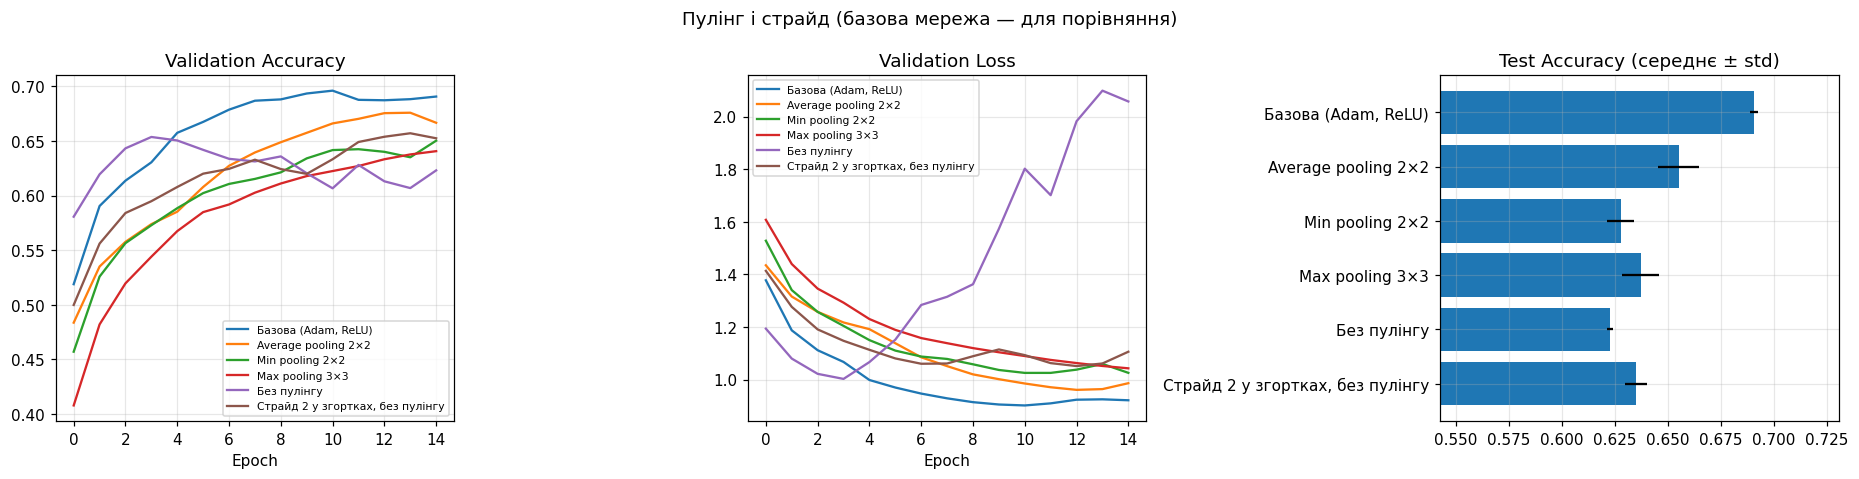

                           назва  train_acc  val_acc  test_acc  test_std  розрив  параметри    час_с
             Базова (Adam, ReLU)     0.7717   0.6925    0.6904    0.0019  0.0793     315722  39.0183
             Average pooling 2×2     0.7332   0.6625    0.6551    0.0098  0.0707     315722  40.5158
                 Min pooling 2×2     0.7063   0.6416    0.6277    0.0063  0.0647     315722  46.7391
                 Max pooling 3×3     0.6569   0.6376    0.6371    0.0086  0.0193      53578  27.1318
                     Без пулінгу     0.9667   0.6232    0.6225    0.0015  0.3435    6443338 154.0086
Страйд 2 у згортках, без пулінгу     0.7917   0.6359    0.6349    0.0052  0.1558     422218  15.7799


In [20]:
POOLS = [
    ('Average pooling 2×2',               dict(pool='avg')),
    ('Min pooling 2×2',                   dict(pool='min')),
    ('Max pooling 3×3',                   dict(pool_size=3)),
    ('Без пулінгу',                       dict(pool='none')),
    ('Страйд 2 у згортках, без пулінгу',  dict(conv_stride=2, pool='none')),
]
for name, arch in POOLS:
    run_experiment(name, 'пулінг і страйд', **arch)
show_group('пулінг і страйд', 'Пулінг і страйд (базова мережа — для порівняння)')

In [21]:
for name, arch in POOLS:
    m = build_cnn(**arch)
    flat = [l for l in m.layers if isinstance(l, Flatten)][0].output.shape[1]
    print(f'{name:<36} Flatten: {flat:>6}   параметрів: {m.count_params():>9,}')
    keras.backend.clear_session()

Average pooling 2×2                  Flatten:   2304   параметрів:   315,722


Min pooling 2×2                      Flatten:   2304   параметрів:   315,722


Max pooling 3×3                      Flatten:    256   параметрів:    53,578


Без пулінгу                          Flatten:  50176   параметрів: 6,443,338


Страйд 2 у згортках, без пулінгу     Flatten:   3136   параметрів:   422,218


## Завдання 4. Аналіз результатів і рекомендації
> Аналіз результатів: Візуалізувати криві навчання та втрат, розрахувати метрики, проаналізувати результати, надати рекомендації щодо можливих покращень моделі.

### 4.1 Зведена таблиця всіх експериментів

              група                             назва  train_acc  val_acc  test_acc  test_std  розрив  параметри
0       архітектура    Блоки 2×Conv (32-64-128), same     0.9049   0.7451    0.7384    0.0104  0.1598     550570
1       архітектура     3 згорткові (32-64-128), same     0.8337   0.7137    0.7131    0.0055  0.1199     356810
2       архітектура                   Широка (64-128)     0.8151   0.6979    0.6985    0.0034  0.1172     666890
3       архітектура             Базова + padding same     0.7992   0.6962    0.6922    0.0027  0.1030     545098
4       оптимізатор                           RMSprop     0.8083   0.6965    0.6905    0.0074  0.1118     315722
5              база               Базова (Adam, ReLU)     0.7717   0.6925    0.6904    0.0019  0.0793     315722
6         активація                        leaky_relu     0.8148   0.6867    0.6902    0.0080  0.1282     315722
7     регуляризація                       L2 (0.0001)     0.7648   0.6887    0.6859    0.0053  0

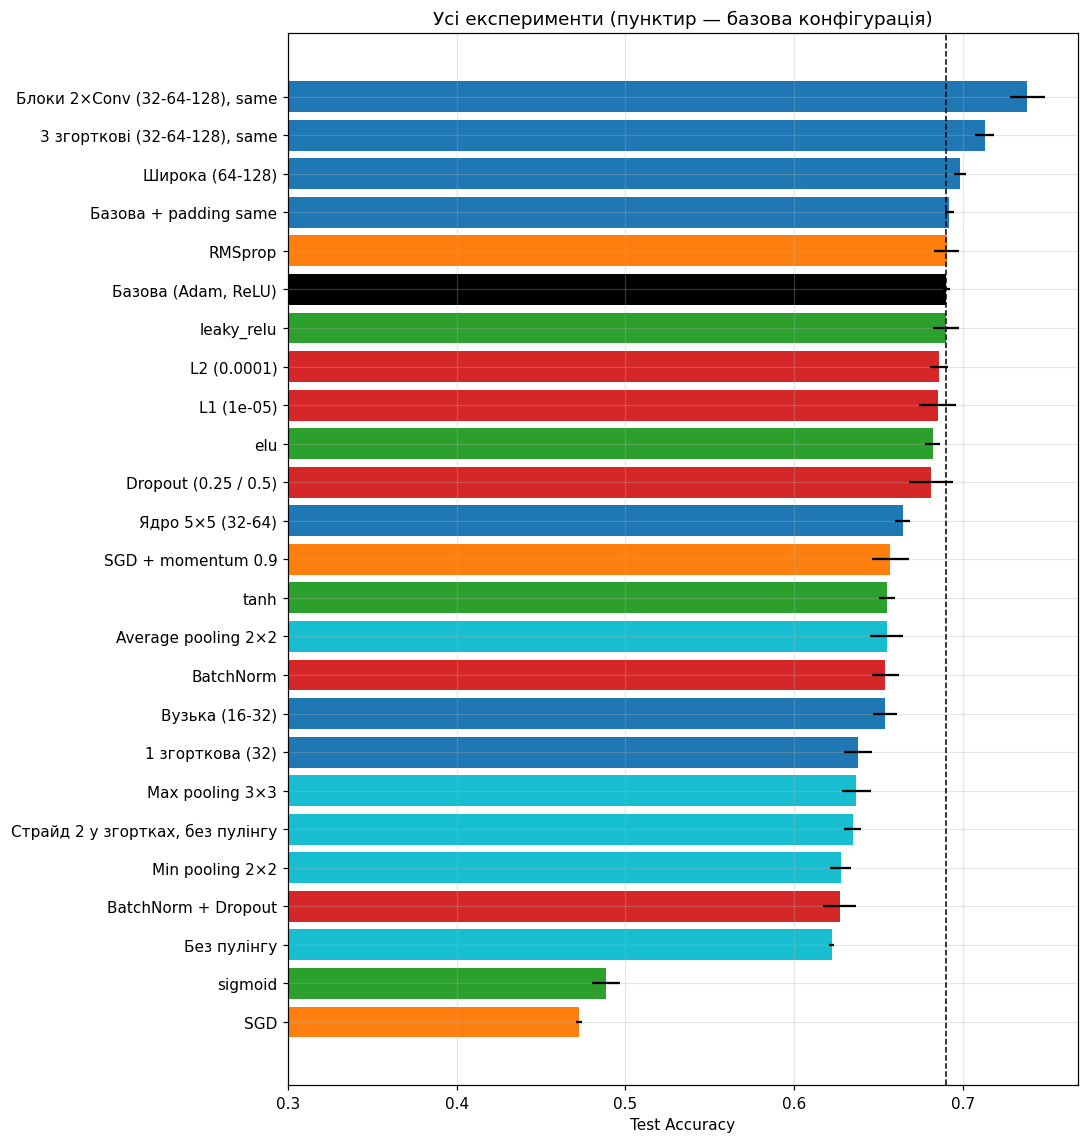

In [22]:
results_df = pd.DataFrame(results)
summary = results_df.sort_values('test_acc', ascending=False).reset_index(drop=True)
cols = ['група', 'назва', 'train_acc', 'val_acc', 'test_acc', 'test_std', 'розрив', 'параметри']
print(summary[cols].round(4).to_string())

colors = {'база': 'black', 'оптимізатор': 'tab:orange', 'активація': 'tab:green',
          'регуляризація': 'tab:red', 'архітектура': 'tab:blue', 'рекомендована': 'tab:purple',
          'пулінг і страйд': 'tab:cyan'}
plt.figure(figsize=(10, 10.5))
s = summary.iloc[::-1]
plt.barh(s['назва'], s['test_acc'], xerr=s['test_std'], color=[colors[g] for g in s['група']])
plt.axvline(results_df.loc[results_df['база'], 'test_acc'].iloc[0], color='k', ls='--', lw=1)
plt.xlim(0.3, s['test_acc'].max() + 0.03)
plt.xlabel('Test Accuracy'); plt.title('Усі експерименти (пунктир — базова конфігурація)')
plt.tight_layout()
plt.show()

### 4.2 Розрив train − val (перенавчання) по групах

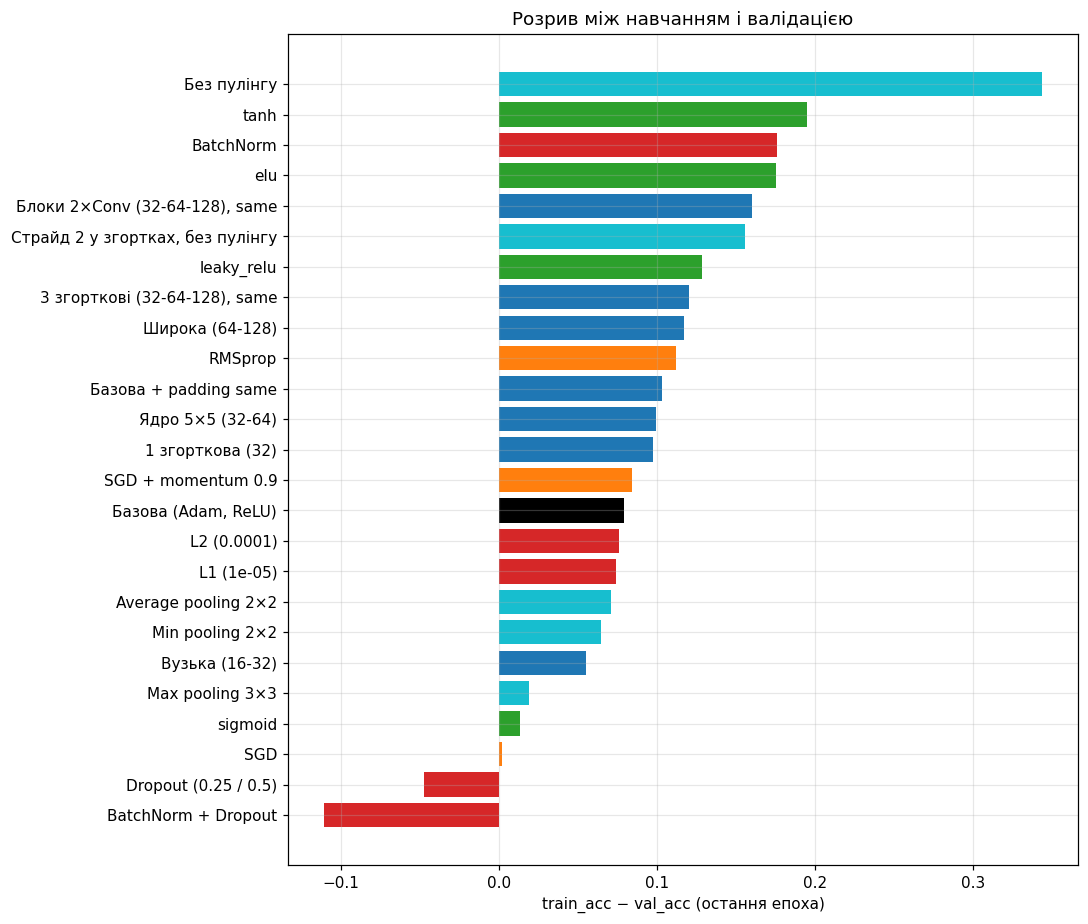

In [23]:
fig, ax = plt.subplots(figsize=(10, 8.5))
g = results_df.sort_values('розрив').reset_index(drop=True)
ax.barh(g['назва'], g['розрив'], color=[colors[x] for x in g['група']])
ax.set_xlabel('train_acc − val_acc (остання епоха)')
ax.set_title('Розрив між навчанням і валідацією')
plt.tight_layout()
plt.show()

### 4.3 Рекомендована модель: комбінація найкращих рішень

In [24]:
BEST_NAME = 'Рекомендована: 2×Conv + BN + Dropout'
BEST_ARCH = dict(filters=(32, 64, 128), padding='same', double=True, batchnorm=True, dropout=True)
run_experiment(BEST_NAME, 'рекомендована', keep_pred=True, **BEST_ARCH)

yp = np.argmax(preds[BEST_NAME], axis=1)
results_df = pd.DataFrame(results)
print(f'Рекомендована: тест {results[-1]["test_acc"] * 100:.2f}% (середнє за {N_RUNS} запуски), '
      f'базова: {results_df.loc[results_df["база"], "test_acc"].iloc[0] * 100:.2f}%')

results_df.to_csv('outputs/results.csv', index=False, encoding='utf-8')
with open('outputs/histories.json', 'w', encoding='utf-8') as f:
    json.dump(histories, f, ensure_ascii=False)

рекомендована  Рекомендована: 2×Conv + BN + Dropout   train=0.7112  val=0.7449  test=0.7389±0.0154  параметри=552,362  371 с/запуск
Рекомендована: тест 73.89% (середнє за 3 запуски), базова: 69.04%


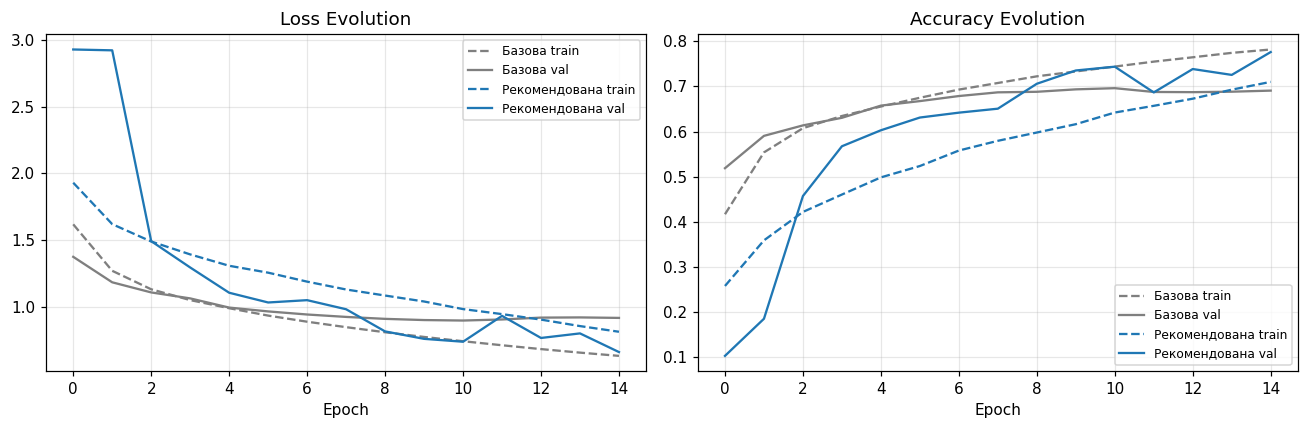

In [25]:
plt.figure(figsize=(12, 4))
bh = histories[BEST_NAME]
for k, (key, ttl) in enumerate([('loss', 'Loss'), ('accuracy', 'Accuracy')]):
    plt.subplot(1, 2, k + 1)
    plt.plot(history.history[key], '--', color='tab:gray', label='Базова train')
    plt.plot(history.history['val_' + key], color='tab:gray', label='Базова val')
    plt.plot(bh[key], '--', color='tab:blue', label='Рекомендована train')
    plt.plot(bh['val_' + key], color='tab:blue', label='Рекомендована val')
    plt.title(ttl + ' Evolution'); plt.xlabel('Epoch'); plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

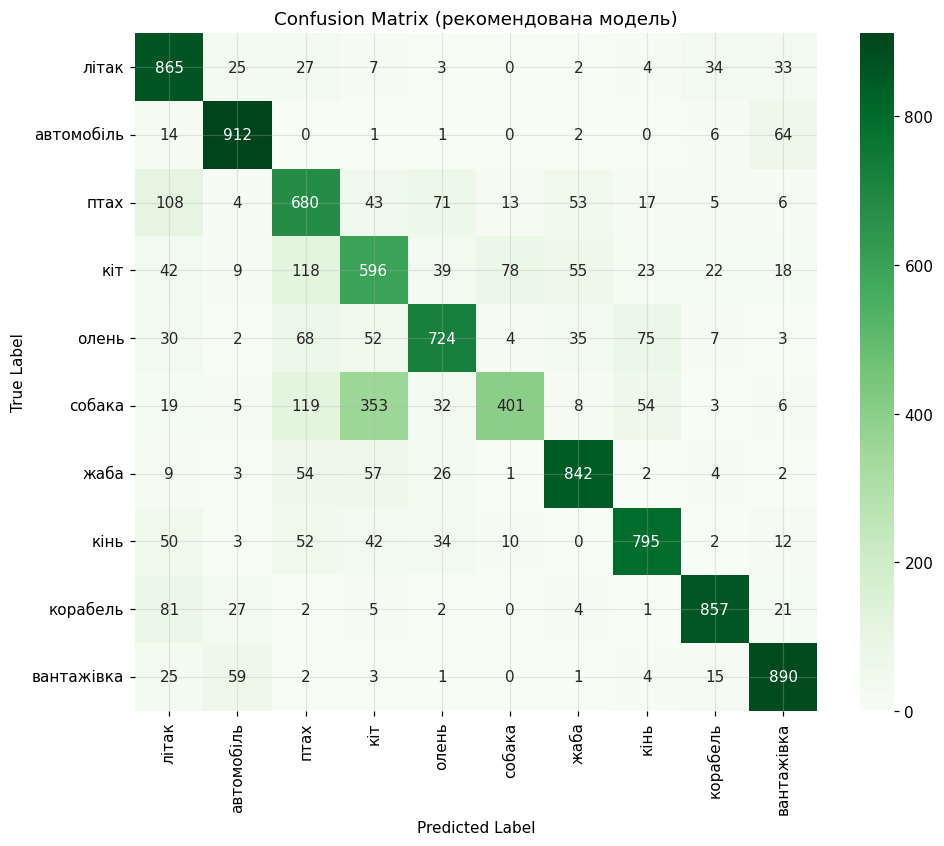

              precision    recall  f1-score   support

       літак     0.6959    0.8650    0.7713      1000
  автомобіль     0.8694    0.9120    0.8902      1000
        птах     0.6061    0.6800    0.6409      1000
         кіт     0.5142    0.5960    0.5521      1000
       олень     0.7760    0.7240    0.7491      1000
      собака     0.7909    0.4010    0.5322      1000
        жаба     0.8403    0.8420    0.8412      1000
        кінь     0.8154    0.7950    0.8051      1000
    корабель     0.8974    0.8570    0.8767      1000
  вантажівка     0.8436    0.8900    0.8662      1000

    accuracy                         0.7562     10000
   macro avg     0.7649    0.7562    0.7525     10000
weighted avg     0.7649    0.7562    0.7525     10000



In [26]:
cm_b = confusion_matrix(y_true, yp)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_b, annot=True, fmt='d', cmap='Greens',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted Label'); plt.ylabel('True Label'); plt.title('Confusion Matrix (рекомендована модель)')
plt.show()

print(classification_report(y_true, yp, target_names=CLASS_NAMES, digits=4, zero_division=0))
f1_best = classification_report(y_true, yp, target_names=CLASS_NAMES, output_dict=True, zero_division=0)

            F1 базова  F1 рекомендована  приріст
літак          0.7369            0.7713   0.0343
автомобіль     0.8087            0.8902   0.0815
птах           0.5927            0.6409   0.0482
кіт            0.4779            0.5521   0.0742
олень          0.6469            0.7491   0.1022
собака         0.5868            0.5322  -0.0546
жаба           0.7496            0.8412   0.0916
кінь           0.7141            0.8051   0.0910
корабель       0.8042            0.8767   0.0725
вантажівка     0.7769            0.8662   0.0893


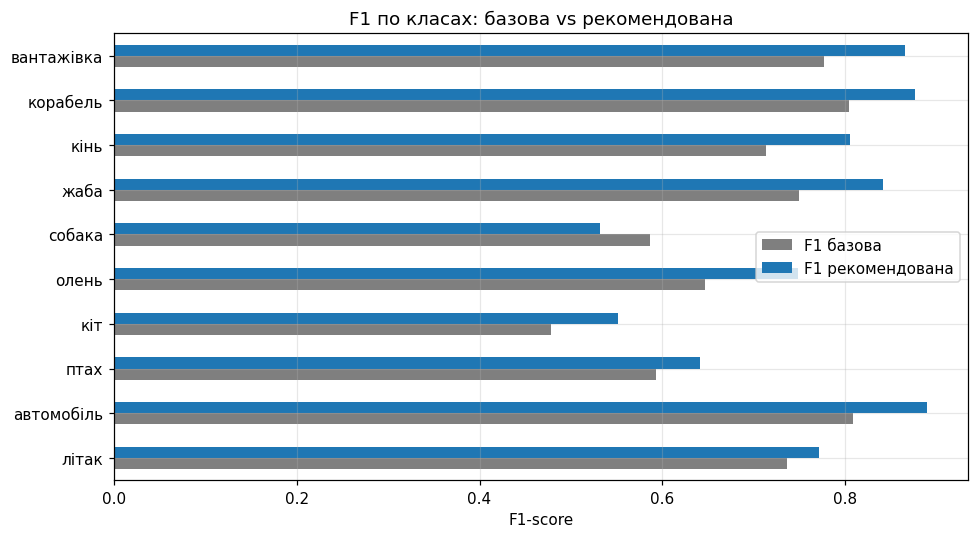

In [27]:
cmp = pd.DataFrame({'F1 базова': [f1_base[c]['f1-score'] for c in CLASS_NAMES],
                    'F1 рекомендована': [f1_best[c]['f1-score'] for c in CLASS_NAMES]},
                   index=CLASS_NAMES)
cmp['приріст'] = cmp['F1 рекомендована'] - cmp['F1 базова']
print(cmp.round(4).to_string())
cmp[['F1 базова', 'F1 рекомендована']].plot.barh(figsize=(9, 5), color=['tab:gray', 'tab:blue'])
plt.title('F1 по класах: базова vs рекомендована'); plt.xlabel('F1-score')
plt.tight_layout()
plt.show()